# Tutorial 3 - DSS colitis: the inflammation marker trend of each mouse over time

A MERFISH time course of mouse colon through DSS-induced colitis and its resolution: healthy,
day 3, day 9 and day 21, across **52 sections from 15 animals**. One temporal model is fitted
over the whole course.

### What this notebook reproduces

The **per-mouse inflammation trajectory**: for each animal, the predicted DSS-marker score of its
own cells re-decoded at day 0, 3, 9 and 21 - a longitudinal curve for an animal that was
measured exactly once.

That is the point of the experiment. The sampling is terminal: every mouse is killed at one
timepoint, so a measured trajectory for an individual animal **does not exist in the data and
cannot be constructed from it**. The model supplies the counterfactual: *given this animal's
tissue architecture, what would its inflammation look like at a day it was never measured at?*

### How the model produces it

The response is written as

```
response(t)  =  amplitude(t)  x  spatial field(lengthscale(t))  x  perturbation effect
```

so a single model covers all four timepoints and can be asked for one it was never trained on.
Three settings fix the direction and magnitude of the inflammation response, which the likelihood
alone does not identify:

* a per-cell inflammation field supervised against the observed marker score, so the magnitude is
  tied to measured inflammation rather than free;
* the field's **time input is frozen** - each section carries exactly one day, so "healthy
  architecture at day 9" never appears in the data. Time still enters through the spatial field,
  which is where the rise and the resolution are learned;
* the sign of the effect is constrained positive **on the inflammation marker panel only** - the
  remaining genes stay free, because resolution genuinely lowers some of them.

The re-decode is deliberately **leakage-free**: the basal state is rebuilt from the cell's tissue
architecture codes, never from its own expression, and only the time input `t` varies between the
four decodes. So any movement in the predicted marker score is attributable to the field, not to
the cell's measured inflammation leaking through.

### The readout

`obs_score = mean over the marker panel of log1p(counts)`, per cell, averaged per mouse. The
prediction uses the same formula on the decoded counts, so the two are on the same scale.

## 0. Before you start

Sections 1-5 and 7 onward are **CPU-only** - they read the checkpoint header and the result
tables, and draw the figures. Only section 6, which re-runs the decode, needs a GPU.

```bash
# one GPU node from your scheduler, then start Jupyter inside it
conda activate concert_env        # built from env_requirements.txt (main README, "Run CONCERT")
# data/ and checkpoints/ sit in the repository root (or set CONCERT_DATA_DIR / CONCERT_CHECKPOINT_ROOT)
jupyter lab --no-browser --ip=0.0.0.0
```

Re-decoding all 15 mice (1.35 M cells, four virtual days) takes roughly 30-45 minutes on one
H100 and about 200 GB of host memory. Section 6 is off by default and the notebook reads the
shipped result instead; a reduced-cohort run is offered for anyone who wants to see it happen.

## 1. Paths

`checkpoints/dss_colitis` is **the** case-study checkpoint: trained on all 15 animals with the
field's time input frozen.

In [1]:
import os, sys, json, csv, subprocess, shutil
from pathlib import Path

# The repository root: the directory holding models/ and benchmark_evaluation/. Found by
# walking up from the working directory, so the notebook runs from anywhere inside the repo;
# set CONCERT_CODEBASE to override. Every other root below reads an environment variable too,
# with the paths these results were produced on as the fallback -- see datasets/README.md.
def _repo_root():
    env = os.environ.get("CONCERT_CODEBASE")
    if env:
        return Path(env)
    for d in [Path.cwd(), *Path.cwd().parents]:
        if (d / "models" / "concert_benchmark").is_dir():
            return d
    raise RuntimeError("cannot locate the repository root; set CONCERT_CODEBASE")

def _root(var, default):
    return Path(os.environ.get(var, default))

CODEBASE  = _repo_root()
MODEL_SRC = CODEBASE / "models" / "concert_temporal"        # the temporal model variant
EXP       = CODEBASE / "experiments" / "03_dss_gut_case_study"

# Every input sits in the downloadable data/ and checkpoints/ folders; release_paths.py defines
# their layout and reads CONCERT_DATA_DIR and CONCERT_CHECKPOINT_ROOT.
sys.path.insert(0, str(CODEBASE / "benchmark_evaluation"))
import release_paths as rp

DSS_DIR   = rp.DSS / "sections"                             # the MERFISH sections
ARCH_DIR  = rp.DSS / "architecture"                         # tissue-architecture descriptors
MANIFEST  = DSS_DIR / "manifest.csv"

RUN       = rp.CHECKPOINTS / "dss_colitis"                  # the case-study checkpoint
CKPT      = RUN / "model.pt"
SHIPPED   = rp.DSS / "case_study"                           # C1-C3 outputs of that checkpoint
HELDOUT   = rp.DSS / "heldout_eval"                         # per-cell decodes of the held-out mice

PAPER_NUMBERS = rp.DSS / "paper_numbers"

WORKDIR = Path(os.environ.get(
    "CONCERT_NB_WORKDIR",
    f"{rp.WORKDIR}/notebook_runs/03_dss_colitis"))
WORKDIR.mkdir(parents=True, exist_ok=True)

checks = [
    ("temporal model source", MODEL_SRC / "concert_spac.py"),
    ("case-study evaluation", EXP / "evaluation" / "case_study_eval.py"),
    ("figure style",          EXP / "figures" / "paper_style.py"),
    ("section manifest",      MANIFEST),
    ("architecture codes",    ARCH_DIR),
    ("checkpoint",            CKPT),
    ("vocabulary",            RUN / "pert_map.json"),
    ("architecture scaler",   RUN / "arch_scaler.npz"),
    ("shipped trajectories",  SHIPPED / "per_mouse_trajectories.csv"),
    ("observed anchors",      SHIPPED / "per_mouse_observed.csv"),
    ("mouse label map",       PAPER_NUMBERS / "mouse_id_map.csv"),
    ("readout calibration",   PAPER_NUMBERS / "calibration.json"),
]
for label, p in checks:
    print(f"{'OK ' if p.exists() else 'MISSING':>8}  {label:<22}  {rp.show(p)}")
print(f"\ncheckpoint size: {CKPT.stat().st_size / 1e9:.2f} GB")
print(f"notebook output dir: {rp.show(WORKDIR)}")

     OK   temporal model source   <repo>/models/concert_temporal/concert_spac.py
     OK   case-study evaluation   <repo>/experiments/03_dss_gut_case_study/evaluation/case_study_eval.py
     OK   figure style            <repo>/experiments/03_dss_gut_case_study/figures/paper_style.py
     OK   section manifest        $CONCERT_DATA_DIR/dss_colitis/sections/manifest.csv
     OK   architecture codes      $CONCERT_DATA_DIR/dss_colitis/architecture
     OK   checkpoint              $CONCERT_CHECKPOINT_ROOT/dss_colitis/model.pt
     OK   vocabulary              $CONCERT_CHECKPOINT_ROOT/dss_colitis/pert_map.json
     OK   architecture scaler     $CONCERT_CHECKPOINT_ROOT/dss_colitis/arch_scaler.npz
     OK   shipped trajectories    $CONCERT_DATA_DIR/dss_colitis/case_study/per_mouse_trajectories.csv
     OK   observed anchors        $CONCERT_DATA_DIR/dss_colitis/case_study/per_mouse_observed.csv
     OK   mouse label map         $CONCERT_DATA_DIR/dss_colitis/paper_numbers/mouse_id_map.csv
     O

## 2. The cohort

The manifest is the source of truth for which section belongs to which animal and which day. Its
column order matters to the run scripts: filename first, animal third, timepoint fourth.

Note how uneven the design is - three animals at day 0, four at day 3, six at day 9, two at day
21 - and that day 9 is where the sections pile up. Any per-day mean is weighted by that.

In [2]:
import pandas as pd
import numpy as np

man = pd.read_csv(MANIFEST)
cohort = (man.groupby(["Mouse_ID", "Sample_type", "day"])
            .agg(n_sections=("file", "size"), n_cells=("n_cells", "sum"))
            .reset_index().sort_values(["day", "Mouse_ID"]))

labels = pd.read_csv(PAPER_NUMBERS / "mouse_id_map.csv")   # figure_label, mouse_id, day
cohort = cohort.merge(labels[["figure_label", "mouse_id"]],
                      left_on="Mouse_ID", right_on="mouse_id", how="left").drop(columns="mouse_id")

print(f"{len(man)} sections, {cohort.Mouse_ID.nunique()} animals, {cohort.n_cells.sum():,} cells")
print(cohort.groupby("day").agg(n_mice=("Mouse_ID", "size"),
                                n_sections=("n_sections", "sum"),
                                n_cells=("n_cells", "sum")).to_string())
cohort[["figure_label", "Mouse_ID", "Sample_type", "day", "n_sections", "n_cells"]]

52 sections, 15 animals, 1,348,582 cells
      n_mice  n_sections  n_cells
day                              
0.0        3          10   239450
3.0        4          13   299274
9.0        6          25   660977
21.0       2           4   148881


,figure_label,Mouse_ID,Sample_type,day,n_sections,n_cells
0,Mouse 1,062921_D0_m3a,Healthy,0.0,5,133081
1,Mouse 2,082421_D0_m6,Healthy,0.0,3,70000
2,Mouse 3,082421_D0_m7,Healthy,0.0,2,36369
3,Mouse 4,092421_D3_m1,DSS3,3.0,3,83828
4,Mouse 5,092421_D3_m2,DSS3,3.0,3,84850
5,Mouse 6,092421_D3_m3,DSS3,3.0,4,70949
6,Mouse 7,092421_D3_m4,DSS3,3.0,3,59647
7,Mouse 8,062221_D9_m3,DSS9,9.0,3,82479
8,Mouse 9,062921_D9_m2a,DSS9,9.0,3,74125
9,Mouse 10,062921_D9_m5,DSS9,9.0,6,182804


## 3. Open the checkpoint

No inference yet - this just confirms which model is on disk and that it carries the temporal
machinery. The tensors to look for are the time embedding (the Fourier features of `t`) and the
inflammation-field head; their presence is what distinguishes this variant from the benchmark
model used in tutorials 1 and 2.

In [3]:
import torch

sd = torch.load(str(CKPT), map_location="cpu", weights_only=False)
if isinstance(sd, dict) and "model_state_dict" in sd:
    sd = sd["model_state_dict"]

print(f"{len(sd)} tensors, {sum(v.numel() for v in sd.values() if hasattr(v, 'numel')):,} parameters\n")
for pat in ("time", "field", "amp", "niche", "fpert", "arch", "tier1"):
    hits = [k for k in sd if pat in k.lower()]
    if hits:
        print(f"{pat:<8} {len(hits):>3} tensors, e.g. {hits[0]}  {tuple(sd[hits[0]].shape)}")

print("\nperturbation vocabulary:", json.loads((RUN / "pert_map.json").read_text())["pert_map"])

108 tensors, 348,406,704 parameters

time      12 tensors, e.g. time_embed.freqs  (6,)
field     16 tensors, e.g. fpert_field.Z  (16, 2)
amp        4 tensors, e.g. amp_time.mlp.0.weight  (16, 16)
niche      8 tensors, e.g. niche_descriptor.proj.weight  (32, 8)
fpert      8 tensors, e.g. fpert_field.Z  (16, 2)
arch       4 tensors, e.g. W_arch_basal.weight  (256, 20)
tier1      1 tensors, e.g. E_tier1.weight  (8, 256)

perturbation vocabulary: {'__basal__': 0, 'perturbed': 1}


## 4. The marker panel

The readout is the mean of `log1p(counts)` over a fixed panel of inflammation genes. The panel is
hard-coded in the evaluation so the observed and predicted sides cannot drift apart.

Two panels appear in the code and they are **not** interchangeable:

* the **20-gene** panel used by the model-side re-decode (`case_study_eval.py`), and
* the **17-gene** panel used by the model-free observed anchors (`compute_observed_per_mouse.py`),
  which drops `S100a8`, `S100a9` and `Ly6a`.

Anywhere the two are compared numerically, the 17-gene version is the one used on both sides.

In [4]:
MARKERS_20 = ['Isg15', 'Ifit1', 'Tnf', 'Cxcl1', 'Nos2', 'Il11', 'Il1b', 'Mmp3', 'Mmp10',
              'Mmp13', 'Plau', 'Igfbp5', 'Col18a1', 'Mmp2', 'S100a8', 'S100a9', 'Osm',
              'Cxcl10', 'Cxcl5', 'Ly6a']
MARKERS_17 = [g for g in MARKERS_20 if g not in {'S100a8', 'S100a9', 'Ly6a'}]
DAYS = [0, 3, 9, 21]

print("re-decode panel (20):", ", ".join(MARKERS_20))
print("\nobserved-anchor panel (17):", ", ".join(MARKERS_17))

re-decode panel (20): Isg15, Ifit1, Tnf, Cxcl1, Nos2, Il11, Il1b, Mmp3, Mmp10, Mmp13, Plau, Igfbp5, Col18a1, Mmp2, S100a8, S100a9, Osm, Cxcl10, Cxcl5, Ly6a

observed-anchor panel (17): Isg15, Ifit1, Tnf, Cxcl1, Nos2, Il11, Il1b, Mmp3, Mmp10, Mmp13, Plau, Igfbp5, Col18a1, Mmp2, Osm, Cxcl10, Cxcl5


## 5. Reproducing the trajectories - what the job actually does

The per-mouse trajectories are deliverable **C1** of `run_case_study_deliverables`, reached from
`run_concert_spac.py --stage composition_eval --case_study_deliverables True`. For each virtual
day `t` in {0, 3, 9, 21} it calls the model once over **every** cell:

```python
mu, _ = model.counterfactualPrediction(
    X=pos_batched, sample_index=sample_indices, cell_atts=cell_atts,
    perturb_cell_id=arange(N),
    target_cell_perturbation=pert_code, target_has_guide=True, target_is_real_KO=True,
    n_samples=3, Y=Y_expr, time_t=full(N, t / 21.0),      # <- the only thing that changes
    tier1_id=tier1_codes, arch_desc=arch_codes)           # <- leakage-free basal
score_t = log1p(mu * size_factor)[:, marker_idx].mean(1)
```

Two details that are easy to get wrong:

* **`mu` is size-factor normalized.** The negative-binomial mean is `mu * size_factor`, so the
  size factor has to be multiplied back before taking `log1p`, or the prediction is not in count
  space and is not comparable to the observed score. The size factor is per cell and independent
  of time, so it cannot change the *shape* of the day profile - only its level, which is exactly
  what makes the comparison to counts meaningful.
* **`tier1_id` and `arch_desc` are required** whenever the model uses the shared basal state.
  They are the tissue-architecture codes; passing the cell's own expression instead would leak
  the measured inflammation into the prediction and make the trajectory meaningless.

Then C1 averages `score_t` per animal and writes `per_mouse_trajectories.csv`.

### Running it

`composition_eval` loads `<outdir>/model.pt`, so `--outdir` has to be a directory containing the
checkpoint. Rather than writing into the checkpoint's own directory - which is
close to its group quota, and where a failed write can truncate the target - the cell below
builds a **symlink shadow** of that directory under `WORKDIR` and writes there.

`RUN_DECODE` is off by default. Set it to `True` to run it; `MICE_SUBSET` keeps the cost down by
restricting the cohort (the trajectories are per animal, so a subset changes nothing about the
animals it does include, only which ones you get).

In [5]:
RUN_DECODE  = False               # True -> re-run the decode on a GPU
MICE_SUBSET = ["082421_D0_m6", "092421_D3_m1", "100221_D9_m5", "082421_D21_m1"]  # one per day
                                  # set to None for all 15 animals (~30-45 min, ~200 GB RAM)

shadow = WORKDIR / "ckpt_shadow"
shadow.mkdir(parents=True, exist_ok=True)
for f in RUN.iterdir():                       # symlink the checkpoint and its sidecar files
    if f.is_file() and not (shadow / f.name).exists():
        (shadow / f.name).symlink_to(f)

mice = MICE_SUBSET or sorted(man.Mouse_ID.unique())
files = [str(DSS_DIR / f) for f in man[man.Mouse_ID.isin(mice)].file]
print(f"{len(mice)} animals, {len(files)} sections")

cmd = [
    sys.executable, "-u", "run_concert_spac.py", "--stage", "composition_eval",
    "--config", "config.yaml", "--sample", "dss_notebook",
    "--multi_sample_files", ",".join(files),
    "--outdir", str(shadow), "--model_file", "model.pt", "--project_index", "dss",
    "--case_study_deliverables", "True",
    # architecture: must match the training flags or the weights will not load
    "--use_timekernel", "True", "--use_shared_basal", "True", "--use_time_intensity", "False",
    "--arch_desc_dir", str(ARCH_DIR),
    "--use_inflammation_field", "True", "--field_mse_lambda", "1.0",
    "--marker_sign_positive", "True", "--time_in_field_mlp", "True",
    "--amp_anchor_offset", "0.0", "--amp_anchor_lambda", "0.0", "--amp_anchor_t", "0.0",
    "--use_time_conditioning", "True", "--time_col", "day_norm",
    "--time_fourier_bands", "6", "--time_emb_dim", "16",
    "--hvg_max_rank", "2000", "--seed", "42",
    "--inducing_point_steps", "6", "--grid_inducing_points", "True",
    "--loc_range", "20.0", "--kernel_scale", "10.0", "--multi_kernel_mode", "True",
    "--batch_size", "1024", "--train_size", "0.95",
    "--use_action_correction", "False", "--use_pad", "False", "--min_cells_per_pert", "25",
    "--use_expr_encoder", "True", "--expr_hidden_dims", "512", "256",
    "--use_basal_encoder_only", "True",
    "--dynamicVAE", "False", "--free_bits", "0.5", "--gp_free_bits", "1.0",
    "--use_nngp", "False", "--use_paracrine", "False", "--use_pert_gate", "False",
    "--use_f_pert", "True", "--f_pert_clamp", "5.0",
    "--spatial_basal_only", "True", "--lfc_lambda", "0.0",
    "--basal_field", "rff", "--basal_bayes", "True",
    "--moran_lambda", "1.0", "--disentangle_radius", "4.0",
    "--fpert_field", "gp_pp", "--fpert_coord_scale", "20.0",
    "--fpert_rff_features", "128", "--fpert_rff_bandwidth", "0.15",
    "--ls_prior_lambda", "1.0", "--ls_prior_min", "3", "--ls_prior_max", "18",
    "--fpert_svgp_inducing", "16", "--fpert_svgp_ls_init", "5.0",
    "--verbosity", "1",
]
print("\ncommand:\n ", " ".join(cmd[:8]), "...")

if RUN_DECODE:
    r = subprocess.run(cmd, cwd=str(MODEL_SRC))
    print("exit code", r.returncode)
    FRESH = shadow / "case_study" / "per_mouse_trajectories.csv"
else:
    FRESH = None
    print("\nRUN_DECODE is False -- the shipped result is used below.")

4 animals, 14 sections

command:
  $CONCERT_WORKDIR/concert_env/bin/python -u run_concert_spac.py --stage composition_eval --config config.yaml --sample ...

RUN_DECODE is False -- the shipped result is used below.


## 6. The predicted trajectories

`per_mouse_trajectories.csv` has one row per animal: the day it was actually measured, its cell
count, and the predicted marker score at each of the four virtual days.

**Ignore its `observed_marker_score` column.** That column is a standardised score (it comes out
negative), not the count-space quantity the predictions are in - the two are not comparable. The
observed anchor comes from `per_mouse_observed.csv` in the next section, which is computed from
raw counts with the same formula as the prediction.

In [6]:
traj_path = FRESH if (FRESH and FRESH.exists()) else (SHIPPED / "per_mouse_trajectories.csv")
traj = pd.read_csv(traj_path)
traj = traj.merge(labels[["figure_label", "mouse_id"]], left_on="mouse", right_on="mouse_id",
                  how="left").drop(columns="mouse_id")
traj["mouse_number"] = traj.figure_label.str.extract(r"(\d+)").astype(int)
traj = traj.sort_values("mouse_number")
print("read", rp.show(traj_path), "\n")

pop = {d: traj[f"pred_t{d}"].mul(traj.n_cells).sum() / traj.n_cells.sum() for d in DAYS}
print("population predicted trajectory (cell-weighted):")
for d in DAYS:
    print(f"  day {d:>2}: {pop[d]:.4f}")
print(f"\npeak at day {max(pop, key=pop.get)}")

traj[["figure_label", "mouse", "observed_day", "n_cells"] + [f"pred_t{d}" for d in DAYS]].round(4)

read $CONCERT_DATA_DIR/dss_colitis/case_study/per_mouse_trajectories.csv 

population predicted trajectory (cell-weighted):
  day  0: 0.0819
  day  3: 0.0876
  day  9: 0.3373
  day 21: 0.1833

peak at day 9


,figure_label,mouse,observed_day,n_cells,pred_t0,pred_t3,pred_t9,pred_t21
1,Mouse 1,062921_D0_m3a,0.0,133081,0.0910,0.0958,0.7057,0.3475
4,Mouse 2,082421_D0_m6,0.0,70000,0.0828,0.0884,0.2988,0.1476
5,Mouse 3,082421_D0_m7,0.0,36369,0.0946,0.1020,0.2721,0.1527
8,Mouse 4,092421_D3_m1,3.0,83828,0.0684,0.0728,0.3644,0.1809
9,Mouse 5,092421_D3_m2,3.0,84850,0.0657,0.0683,0.3732,0.1574
10,Mouse 6,092421_D3_m3,3.0,70949,0.0785,0.0824,0.2442,0.1385
11,Mouse 7,092421_D3_m4,3.0,59647,0.0942,0.0961,0.2966,0.1582
0,Mouse 8,062221_D9_m3,9.0,82479,0.0782,0.0837,0.5093,0.2700
2,Mouse 9,062921_D9_m2a,9.0,74125,0.0979,0.1114,0.1505,0.1068
3,Mouse 10,062921_D9_m5,9.0,182804,0.0839,0.0913,0.2598,0.1581


## 7. The observed anchor

Each animal is measured on exactly one day, so the measured value exists on the **diagonal only**
- one point per animal, at its own sampled day. That is the honest comparison point, and the
figures show it beside the prediction rather than showing the prediction alone.

`per_mouse_observed.csv` is produced by `evaluation/compute_observed_per_mouse.py`, which reads
the raw sections and computes `log1p(counts)` over the 17-marker panel - **no model, no GPU**.
The cell below can recompute it from scratch, which is worth doing once because it makes clear
that the observed side owes nothing to the model.

In [7]:
RECOMPUTE_OBSERVED = False        # True -> read the raw sections (slow: a few minutes of I/O)

obs_path = SHIPPED / "per_mouse_observed.csv"
if RECOMPUTE_OBSERVED:
    import anndata as ad, scipy.sparse as sp
    rows = []
    for mid, grp in man.groupby("Mouse_ID"):
        ssum, ncell = 0.0, 0
        for f in grp.file:
            a = ad.read_h5ad(DSS_DIR / f)
            idx = [list(a.var_names).index(g) for g in MARKERS_17]
            X = a.X[:, idx]
            X = X.toarray() if sp.issparse(X) else np.asarray(X)
            s = np.log1p(X).mean(1)
            ssum += float(s.sum()); ncell += s.shape[0]
        rows.append({"mouse": mid, "day": float(grp.day.iloc[0]),
                     "n_cells": ncell, "observed_marker_log1p": ssum / ncell})
    obs = pd.DataFrame(rows)
else:
    obs = pd.read_csv(obs_path)
    print("read", rp.show(obs_path))

obs_by_day = {}
for d in DAYS:
    g = obs[np.isclose(obs.day, d)]
    obs_by_day[d] = float(np.average(g.observed_marker_log1p, weights=g.n_cells))
print("\nobserved marker score, cell-weighted pooled mean per day:")
for d in DAYS:
    print(f"  day {d:>2}: {obs_by_day[d]:.4f}   ({int(np.isclose(obs.day, d).sum())} animals)")
obs.sort_values(["day", "mouse"])

read $CONCERT_DATA_DIR/dss_colitis/case_study/per_mouse_observed.csv

observed marker score, cell-weighted pooled mean per day:
  day  0: 0.0427   (3 animals)
  day  3: 0.0483   (4 animals)
  day  9: 0.0954   (6 animals)
  day 21: 0.0624   (2 animals)


,mouse,day,n_cells,observed_marker_log1p
1,062921_D0_m3a,0.0,133081,0.045975
4,082421_D0_m6,0.0,70000,0.036075
5,082421_D0_m7,0.0,36369,0.043413
8,092421_D3_m1,3.0,83828,0.048076
9,092421_D3_m2,3.0,84850,0.046052
10,092421_D3_m3,3.0,70949,0.048128
11,092421_D3_m4,3.0,59647,0.052125
0,062221_D9_m3,9.0,82479,0.079888
2,062921_D9_m2a,9.0,74125,0.082784
3,062921_D9_m5,9.0,182804,0.119581


## 8. The figure - one virtual trajectory per animal

Each line is one animal's cells re-decoded at the four virtual days, coloured by the day the
animal was actually sampled. The filled marker on each line is that animal's **measured** value,
placed at its own sampled day: the only point where a measurement exists.

Read across the lines, not down them. Every animal rises to a day-9 peak and falls back by day
21, and the animals differ in the **amplitude** of that curve rather than in its shape.

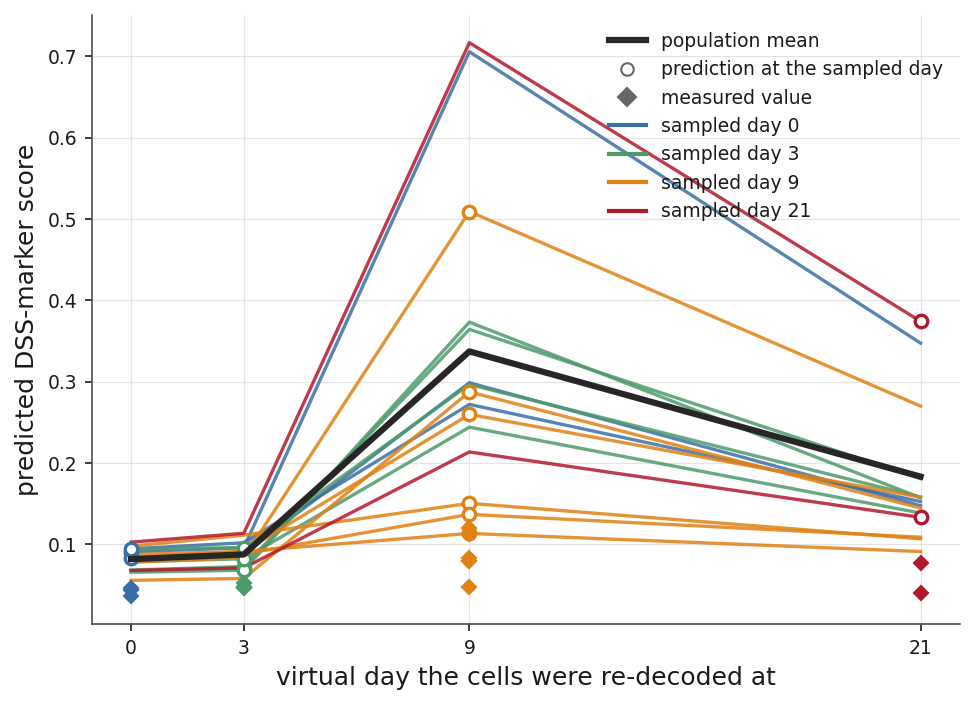

In [8]:
sys.path.insert(0, str(EXP / "figures"))
import paper_style as ps            # the shared day colours and animal labels
ps.use()
# paper_style selects the Agg backend on import, which draws nothing in a notebook.
# Switching back has to come after the import.
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

obs_by_mouse = dict(zip(obs.mouse, obs.observed_marker_log1p))

fig, ax = plt.subplots(figsize=(6.6, 4.8))
for _, r in traj.iterrows():
    c = ps.day_color(r.observed_day)
    ys = [r[f"pred_t{d}"] for d in DAYS]
    ax.plot(DAYS, ys, "-", color=c, lw=1.6, alpha=0.85, zorder=2)
    ax.plot([r.observed_day], [r[f"pred_t{int(r.observed_day)}"]], "o", color=c, ms=6,
            mfc="white", mew=1.6, zorder=3)                       # prediction at its own day
    if r.mouse in obs_by_mouse:
        ax.plot([r.observed_day], [obs_by_mouse[r.mouse]], "D", color=c, ms=5, zorder=4)

ax.plot(DAYS, [pop[d] for d in DAYS], "-", color="0.15", lw=3.0, zorder=5)
ax.set_xticks(DAYS)
ax.set_xlabel("virtual day the cells were re-decoded at", fontsize=12)
ax.set_ylabel("predicted DSS-marker score", fontsize=12)
ax.legend(handles=[Line2D([], [], color="0.15", lw=3, label="population mean"),
                   Line2D([], [], color="0.4", marker="o", mfc="white", ls="none",
                          label="prediction at the sampled day"),
                   Line2D([], [], color="0.4", marker="D", ls="none",
                          label="measured value")] +
                  [Line2D([], [], color=ps.DAY_COLORS[float(d)], lw=2, label=f"sampled day {d}")
                   for d in DAYS],
          fontsize=9, loc="upper right")
fig.tight_layout()
plt.show()

## 9. How far off is the level?

The predicted curve has the right **shape** - it peaks at day 9 and resolves by day 21, matching
the measured population - but it sits above the measured level, and by a factor that is not
constant across days.

This is stated plainly rather than corrected away, because the two facts point in different
directions:

* the **diagonal** - each animal at its own day - is the calibrated quantity, and the figure
  above shows it beside the prediction;
* the **population trajectory at off-days** over-predicts the baseline more than it over-predicts
  the peak, which is a residue of terminal sampling: tissue architecture carries some of the day
  signal, so a day-9 animal's architecture is not neutral when re-decoded at day 0.

Any level claim should quote the diagonal, not the off-day ratios.

,day,predicted,observed,ratio_pred_over_obs,fold_over_day0_pred,fold_over_day0_obs
0,0,0.0819,0.0427,1.9187,1.0000,1.0000
1,3,0.0876,0.0483,1.8139,1.0700,1.1319
2,9,0.3373,0.0954,3.5363,4.1174,2.2341
3,21,0.1833,0.0624,2.9359,2.2381,1.4627


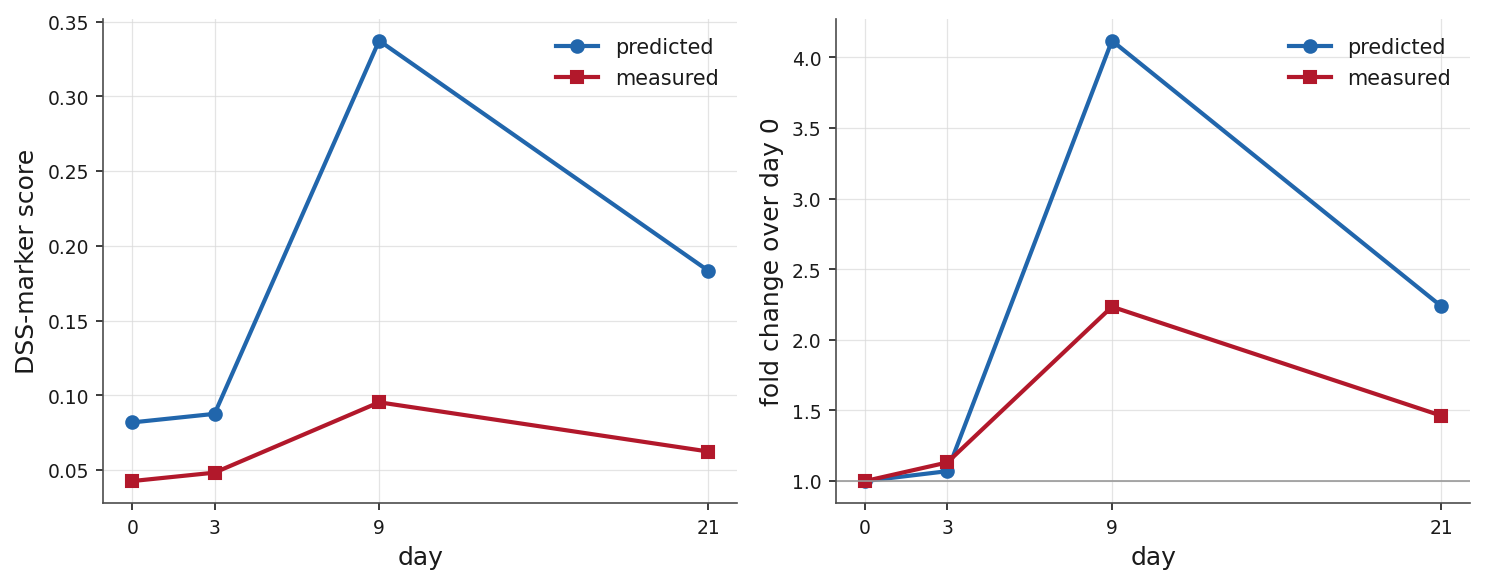

In [9]:
ratio = pd.DataFrame({
    "day": DAYS,
    "predicted": [pop[d] for d in DAYS],
    "observed": [obs_by_day[d] for d in DAYS],
})
ratio["ratio_pred_over_obs"] = ratio.predicted / ratio.observed
ratio["fold_over_day0_pred"] = ratio.predicted / ratio.predicted.iloc[0]
ratio["fold_over_day0_obs"] = ratio.observed / ratio.observed.iloc[0]
display(ratio.round(4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.0))
axes[0].plot(DAYS, ratio.predicted, "-o", color="#2166ac", lw=2, label="predicted")
axes[0].plot(DAYS, ratio.observed, "-s", color=ps.ACCENT, lw=2, label="measured")
axes[0].set_ylabel("DSS-marker score", fontsize=12)
axes[0].legend(fontsize=10)

axes[1].plot(DAYS, ratio.fold_over_day0_pred, "-o", color="#2166ac", lw=2, label="predicted")
axes[1].plot(DAYS, ratio.fold_over_day0_obs, "-s", color=ps.ACCENT, lw=2, label="measured")
axes[1].axhline(1.0, lw=0.8, color="0.6")
axes[1].set_ylabel("fold change over day 0", fontsize=12)
axes[1].legend(fontsize=10)

for ax in axes:
    ax.set_xticks(DAYS)
    ax.set_xlabel("day", fontsize=12)
fig.tight_layout()
plt.show()

## 10. Why linear interpolation cannot produce this

The natural null model for "what did this animal look like at a day it was not measured at" is a
linear interpolation between the two flanking timepoints. Two properties of the predicted
trajectories are outside what such an interpolation can express:

* **the velocity changes sign.** The rate of change of the marker score is positive up to day 9
  and negative after it. A straight line between two static timepoints has one constant slope;
* **the animals differ at a day none of them was measured at.** Interpolating between population
  means gives every animal the same value at day 9 by construction, so the cross-animal spread
  there is exactly zero. The model's spread is not.

,interval,velocity
0,0 to 3,0.00191
1,3 to 9,0.04160
2,9 to 21,-0.01283


sign flip between the day-3-to-9 and day-9-to-21 intervals: True

cross-animal spread of the predicted score at day 9: s.d. 0.1780, range 0.1135 to 0.7168
the same quantity under interpolation between population means: 0.0000 by construction


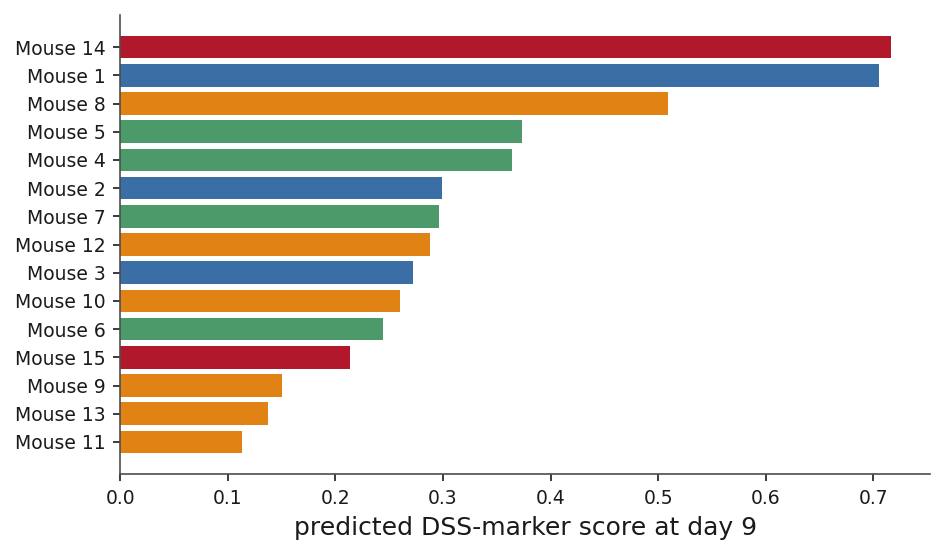

In [10]:
v = pd.DataFrame({
    "interval": ["0 to 3", "3 to 9", "9 to 21"],
    "velocity": [(pop[3] - pop[0]) / 3, (pop[9] - pop[3]) / 6, (pop[21] - pop[9]) / 12],
})
display(v.round(5))
print("sign flip between the day-3-to-9 and day-9-to-21 intervals:",
      bool(np.sign(v.velocity.iloc[1]) != np.sign(v.velocity.iloc[2])))

spread = traj["pred_t9"]
print(f"\ncross-animal spread of the predicted score at day 9: "
      f"s.d. {spread.std(ddof=0):.4f}, range {spread.min():.4f} to {spread.max():.4f}")
print("the same quantity under interpolation between population means: 0.0000 by construction")

fig, ax = plt.subplots(figsize=(6.4, 3.8))
d = traj.sort_values("pred_t9")
ax.barh(d.figure_label, d.pred_t9, color=[ps.day_color(x) for x in d.observed_day])
ax.set_xlabel("predicted DSS-marker score at day 9", fontsize=12)
ax.tick_params(labelsize=9)
ax.grid(False)
fig.tight_layout()
plt.show()

## 11. A marker in space

The trajectories above summarise the 17-marker panel as one score. The map below shows one of the
markers on the tissue: **Cxcl10**, induced 14-fold at day 9 over day 0 in the measurement (pooled
over cells) and back near baseline by day 21, a course the prediction follows.

The section is one of the six of animal `100221_D9_m5`, sampled at day 9. The panels are:

* **Measured** - the expression measured at day 9, the only day this tissue exists in the data;
* **CONCERT, day 0 / 3 / 9 / 21** - the same cells re-decoded at each virtual day.

The day-9 prediction sits beside the measurement, so the two can be compared directly. The other
three days are the virtual time-lapse of a tissue that was measured once. Values are
`log1p` counts at each cell's own size factor, the scale of the marker score. The measured panel
has its own colour range, because single-cell counts are sparse where the prediction is a mean;
the four predicted panels share one range, so they can be read against each other.

The per-cell values come from the shipped `heldout_eval/percell_dump_sizefactor.npz`, written by
the same decode as the trajectories; this section needs no GPU.

100221_D9_m5, section 20: 35,172 cells (the animal has 6 sections, 173,131 cells)


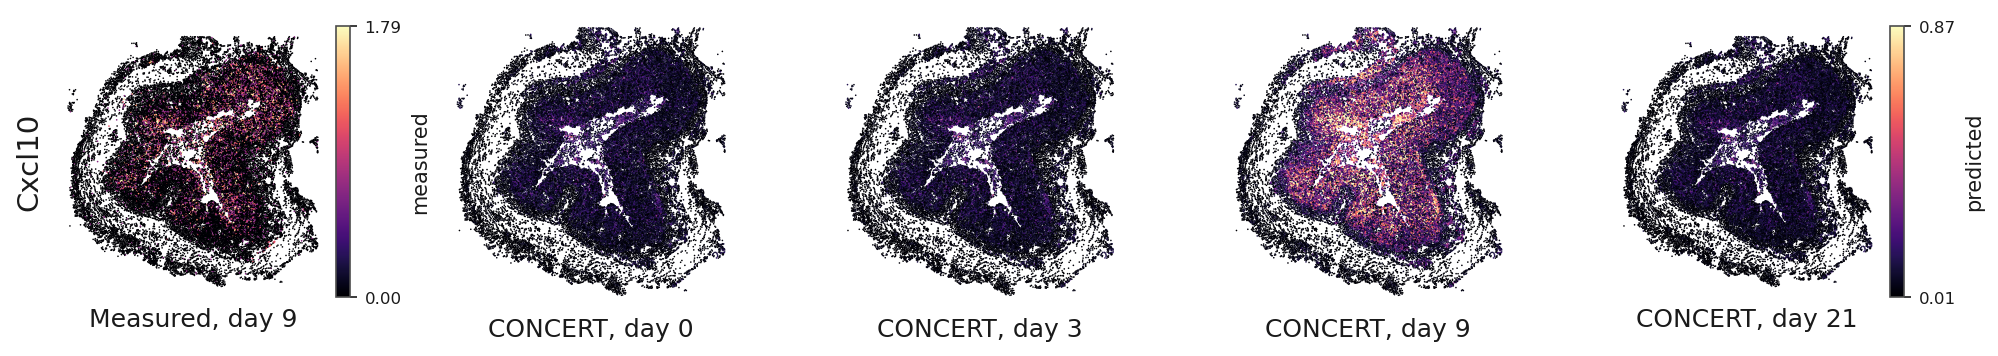

mean over the cells of this section:


,"measured, day 9","predicted, day 0","predicted, day 3","predicted, day 9","predicted, day 21"
Cxcl10,0.1831,0.0617,0.0617,0.2367,0.0627


In [11]:
DUMP = HELDOUT / "percell_dump_sizefactor.npz"
MAP_MOUSE = "100221_D9_m5"
MAP_GENES = ["Cxcl10"]

z = np.load(DUMP, allow_pickle=True)
marker_names = list(z["marker_names"])
in_mouse = z["mouse"] == MAP_MOUSE
sid, n_per = np.unique(z["sample_id"][in_mouse], return_counts=True)
MAP_SECTION = int(sid[np.argmax(n_per)])                  # the animal's largest section
sel = in_mouse & (z["sample_id"] == MAP_SECTION)
xy = z["coords"][sel]
measured = z["obs_marker_expr"][sel]
predicted = {d: z[f"marker_pred_t{d}"][sel] for d in DAYS}
print(f"{MAP_MOUSE}, section {MAP_SECTION}: {int(sel.sum()):,} cells "
      f"(the animal has {len(sid)} sections, {int(in_mouse.sum()):,} cells)")

fig, ax = plt.subplots(len(MAP_GENES), 1 + len(DAYS),
                       figsize=(2.9 * (1 + len(DAYS)) + 1.4, 3.0 * len(MAP_GENES)), squeeze=False)
for r, g in enumerate(MAP_GENES):
    gi = marker_names.index(g)
    vo = np.quantile(measured[:, gi], [0.01, 0.99])
    pv = np.concatenate([predicted[d][:, gi] for d in DAYS])
    vp = np.quantile(pv, [0.01, 0.99])
    h0 = ax[r, 0].scatter(xy[:, 0], xy[:, 1], c=measured[:, gi], s=0.6, lw=0,
                          cmap=ps.FIELD_CMAP, vmin=vo[0], vmax=vo[1], rasterized=True)
    for c, d in enumerate(DAYS, start=1):
        h1 = ax[r, c].scatter(xy[:, 0], xy[:, 1], c=predicted[d][:, gi], s=0.6, lw=0,
                              cmap=ps.FIELD_CMAP, vmin=vp[0], vmax=vp[1], rasterized=True)
    for c in range(1 + len(DAYS)):
        a = ax[r, c]
        a.set_xticks([]); a.set_yticks([]); a.set_aspect("equal"); a.grid(False)
        for sp in a.spines.values():
            sp.set_visible(False)
        if r == len(MAP_GENES) - 1:
            a.set_xlabel("Measured, day 9" if c == 0 else f"CONCERT, day {DAYS[c - 1]}", fontsize=12)
    ax[r, 0].set_ylabel(g, fontsize=14, labelpad=6)
    for h, a, lab in ((h0, ax[r, 0], "measured"), (h1, ax[r, -1], "predicted")):
        cb = fig.colorbar(h, ax=a, fraction=0.046, pad=0.02)
        cb.set_label(lab, fontsize=10); cb.ax.tick_params(labelsize=8)
        cb.set_ticks([cb.vmin, cb.vmax]); cb.ax.set_yticklabels([f"{cb.vmin:.2f}", f"{cb.vmax:.2f}"])
fig.subplots_adjust(wspace=0.32, hspace=0.04)   # room for the measured colour bar
plt.show()

tab = pd.DataFrame({g: {"measured, day 9": measured[:, marker_names.index(g)].mean(),
                        **{f"predicted, day {d}": predicted[d][:, marker_names.index(g)].mean()
                           for d in DAYS}} for g in MAP_GENES}).T
print("mean over the cells of this section:")
tab.round(4)

## What to watch out for

* **`observed_marker_score` in `per_mouse_trajectories.csv` is a standardised score.** It is
  negative and is *not* on the same scale as the predictions. Use `per_mouse_observed.csv` for
  the observed anchor.
* **Multiply the size factor back in.** `counterfactualPrediction` returns a size-factor
  normalized mean; forget the multiplication and the prediction is not in count space. Older
  figures made this mistake and reported a day-9 ratio of about 1.3 where the count-space value
  is about 3.5.
* **The re-decode needs the architecture codes.** `tier1_id` and `arch_desc` must be passed; the
  basal state is keyed by them, and substituting the cell's own expression leaks the measurement
  into the prediction.
* **Two marker panels exist** (20 genes model-side, 17 observed-side). Compare like with like.
* **The predicted spatial structure does not intensify the way the measured one does.** Moran's I
  of the predicted field is high at every day (0.30-0.50) and does not reproduce the measured
  day-9 contiguity peak (0.13 -> 0.27). The model captures the *intensity* peak, not the
  spatial-structure intensification - see `spatial_moran.csv`.
* **Per-animal trajectory shapes are nearly identical.** The heterogeneity is in amplitude and is
  modest. Do not present the curves as showing different disease courses.
* **Storage.** Write under `CONCERT_NB_WORKDIR`. A failed
  write there can truncate the target file to zero.

## Where things are

| | |
|---|---|
| temporal model source | `codebase/models/concert_temporal/` |
| evaluation and figures | `codebase/experiments/03_dss_gut_case_study/` |
| deliverable C1 code | `evaluation/case_study_eval.py`, `run_case_study_deliverables` |
| shipped tables | `data/dss_colitis/case_study/`, `data/dss_colitis/heldout_eval/` |
| reported numbers | `paper_package/numbers/case_study_colitis/` |